# 02. Análise da acessibilidade da cesta básica

## Integrante 2

### Objetivo

Analisar a evolução do custo da cesta básica em comparação
ao salário mínimo, identificando o percentual da renda
comprometido com a alimentação e as variações do poder
de compra ao longo do período analisado.

### Etapas da análise

1. Carregar e verificar os dados da cesta básica.
2. Definir a composição e calcular o custo mensal da cesta.
3. Obter o histórico do salário mínimo.
4. Calcular o comprometimento salarial.
5. Analisar a evolução do poder de compra.
6. Construir gráficos comparativos.
7. Apresentar os resultados e a conclusão.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Configurações dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 110

# Caminho para salvar os gráficos
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


In [4]:
import pandas as pd
from pathlib import Path

# Caminho da base de dados mensal
ARQUIVO = Path("../data/processed/cesta_mensal.csv")

# Carregar os dados
df = pd.read_csv(ARQUIVO)

# Visualizar as primeiras linhas
display(df.head())

# Verificar tamanho da base
print("Dimensões da base:", df.shape)

# Verificar nomes das colunas
print("\nColunas disponíveis:")
print(df.columns.tolist())

# Verificar tipos de dados e valores ausentes
print("\nInformações da base:")
df.info()

,mes,produto,ppk_mediana,ppk_media,n_coletas
0,2022-09-01,Arroz,4.788,4.765714,126
1,2022-09-01,Açúcar,4.390,4.696987,78
2,2022-09-01,Banana Nanica,5.990,6.143529,17
3,2022-09-01,Banana Prata,8.990,8.898000,15
4,2022-09-01,Batata,5.075,5.256429,28


Dimensões da base: (780, 5)

Colunas disponíveis:
['mes', 'produto', 'ppk_mediana', 'ppk_media', 'n_coletas']

Informações da base:
<class 'pandas.DataFrame'>
RangeIndex: 780 entries, 0 to 779
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   mes          780 non-null    str    
 1   produto      780 non-null    str    
 2   ppk_mediana  780 non-null    float64
 3   ppk_media    780 non-null    float64
 4   n_coletas    780 non-null    int64  
dtypes: float64(2), int64(1), str(2)
memory usage: 30.6 KB


In [5]:
# Converter a coluna de mês para formato de data
df["mes"] = pd.to_datetime(df["mes"])

# 1. Período analisado
print("PRIMEIRO MÊS:", df["mes"].min())
print("ÚLTIMO MÊS:", df["mes"].max())
print("TOTAL DE MESES:", df["mes"].nunique())

# 2. Produtos disponíveis
print("\nPRODUTOS DISPONÍVEIS:")
print(sorted(df["produto"].unique()))

print("\nTOTAL DE PRODUTOS:", df["produto"].nunique())

# 3. Quantidade de produtos por mês
print("\nPRODUTOS REGISTRADOS POR MÊS:")
display(
    df.groupby("mes")["produto"]
    .nunique()
    .describe()
)

# 4. Verificar registros duplicados
duplicados = df.duplicated(
    subset=["mes", "produto"]
).sum()

print("\nREGISTROS DUPLICADOS:", duplicados)

# 5. Estatísticas dos preços por produto
estatisticas = (
    df.groupby("produto")["ppk_mediana"]
    .agg(["mean", "min", "max"])
    .round(2)
    .sort_values("mean", ascending=False)
)

display(estatisticas)

PRIMEIRO MÊS: 2022-09-01 00:00:00
ÚLTIMO MÊS: 2026-08-01 00:00:00
TOTAL DE MESES: 48

PRODUTOS DISPONÍVEIS:
['Arroz', 'Açúcar', 'Banana Nanica', 'Banana Prata', 'Batata', 'Café', 'Carne Bovina Acém', 'Carne Bovina Coxão Mole', 'Carne Suína Pernil', 'Farinha de Trigo', 'Feijão', 'Frango Peito', 'Frango Sobrecoxa', 'Leite', 'Macarrão', 'Manteiga', 'Ovo', 'Pão Francês', 'Tomate', 'Óleo']

TOTAL DE PRODUTOS: 20

PRODUTOS REGISTRADOS POR MÊS:


count    48.000000
mean     16.250000
std       2.935476
min      14.000000
25%      14.000000
50%      14.000000
75%      20.000000
max      20.000000
Name: produto, dtype: float64


REGISTROS DUPLICADOS: 0


,mean,min,max
produto,,,
Manteiga,68.53,53.16,73.20
Café,50.16,33.70,73.98
Carne Bovina Coxão Mole,45.33,36.79,55.99
Carne Bovina Acém,40.68,37.94,43.99
Frango Peito,23.48,18.24,26.99
Carne Suína Pernil,21.62,18.99,23.99
Frango Sobrecoxa,16.89,15.48,18.49
Pão Francês,16.70,14.98,18.99
Banana Prata,10.55,7.99,12.99


In [6]:
# Carregar a base limpa
ARQUIVO_LIMPO = Path("../data/processed/cesta_limpa.csv")

df_limpo = pd.read_csv(ARQUIVO_LIMPO)

# Verificar dimensões
print("DIMENSÕES:", df_limpo.shape)

# Verificar todas as colunas
print("\nCOLUNAS DISPONÍVEIS:")
print(df_limpo.columns.tolist())

# Verificar tipos de dados
print("\nINFORMAÇÕES:")
df_limpo.info()

# Visualizar os primeiros registros
print("\nPRIMEIROS REGISTROS:")
display(df_limpo.head(10))

# Verificar os produtos disponíveis
print("\nPRODUTOS:")
print(sorted(df_limpo["produto"].dropna().unique()))

DIMENSÕES: (44491, 8)

COLUNAS DISPONÍVEIS:
['mes', 'data_coleta', 'estab', 'produto', 'marca', 'preco', 'quantidade', 'ppk']

INFORMAÇÕES:
<class 'pandas.DataFrame'>
RangeIndex: 44491 entries, 0 to 44490
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   mes          44491 non-null  str    
 1   data_coleta  34927 non-null  str    
 2   estab        44491 non-null  str    
 3   produto      44491 non-null  str    
 4   marca        35321 non-null  str    
 5   preco        44491 non-null  float64
 6   quantidade   44491 non-null  float64
 7   ppk          44491 non-null  float64
dtypes: float64(3), str(5)
memory usage: 2.7 MB

PRIMEIROS REGISTROS:


,mes,data_coleta,estab,produto,marca,preco,quantidade,ppk
0,2022-09-01,2022-09-23,SUP_33,Carne Bovina Coxão Mole,NaN,54.20,1.0,54.20
1,2022-09-01,2022-09-12,SUP_15,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
2,2022-09-01,2022-09-21,SUP_09,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
3,2022-09-01,2022-09-23,SUP_12,Carne Bovina Coxão Mole,NaN,51.99,1.0,51.99
4,2022-09-01,2022-09-12,SUP_20,Carne Bovina Coxão Mole,NaN,51.90,1.0,51.90
5,2022-09-01,2022-09-26,SUP_13,Carne Bovina Coxão Mole,NaN,50.49,1.0,50.49
6,2022-09-01,2022-09-23,SUP_34,Carne Bovina Coxão Mole,NaN,48.99,1.0,48.99
7,2022-09-01,2022-09-21,SUP_08,Carne Bovina Coxão Mole,NaN,48.90,1.0,48.90
8,2022-09-01,2022-09-23,SUP_36,Carne Bovina Coxão Mole,NaN,47.99,1.0,47.99
9,2022-09-01,2022-09-23,SUP_50,Carne Bovina Coxão Mole,NaN,46.90,1.0,46.90



PRODUTOS:
['Arroz', 'Açúcar', 'Banana Nanica', 'Banana Prata', 'Batata', 'Café', 'Carne Bovina Acém', 'Carne Bovina Coxão Mole', 'Carne Suína Pernil', 'Farinha de Trigo', 'Feijão', 'Frango Peito', 'Frango Sobrecoxa', 'Leite', 'Macarrão', 'Manteiga', 'Ovo', 'Pão Francês', 'Tomate', 'Óleo']


In [7]:
# 1. Resumo das quantidades por produto
resumo_quantidades = (
    df_limpo.groupby("produto")["quantidade"]
    .agg(["count", "nunique", "min", "max", "mean"])
    .round(3)
    .sort_values("nunique", ascending=False)
)

print("QUANTIDADES POR PRODUTO:")
display(resumo_quantidades)

# 2. Exemplos de registros com diferentes quantidades
print("\nEXEMPLOS DE QUANTIDADES POR PRODUTO:")

for produto in sorted(df_limpo["produto"].unique()):
    dados = df_limpo[df_limpo["produto"] == produto]

    print(f"\n{produto}")
    print(
        dados[["preco", "quantidade", "ppk"]]
        .drop_duplicates()
        .head(5)
        .to_string(index=False)
    )

# 3. Verificar se PPK corresponde a preço / quantidade
diferenca = (
    df_limpo["ppk"] -
    (df_limpo["preco"] / df_limpo["quantidade"])
).abs()

print("\nMAIOR DIFERENÇA ENTRE PPK E PREÇO/QUANTIDADE:")
print(diferenca.max())

print("\nREGISTROS COM DIFERENÇA SIGNIFICATIVA:")
print((diferenca > 0.01).sum())

QUANTIDADES POR PRODUTO:


,count,nunique,min,max,mean
produto,,,,,
Manteiga,4653,7,0.20,1.0,0.206
Ovo,451,5,10.00,60.0,13.388
Açúcar,2986,4,0.50,3.0,1.002
Arroz,5076,3,1.00,5.0,4.989
Café,5171,3,0.25,1.0,0.501
Farinha de Trigo,4105,3,0.50,3.0,1.001
Macarrão,1081,2,0.50,1.0,0.619
Banana Nanica,1176,2,0.70,1.0,1.000
Frango Peito,436,2,0.53,1.0,0.998



EXEMPLOS DE QUANTIDADES POR PRODUTO:

Arroz
 preco  quantidade   ppk
 32.98         5.0 6.596
 32.60         5.0 6.520
 30.69         5.0 6.138
 29.99         5.0 5.998
 29.90         5.0 5.980

Açúcar
 preco  quantidade    ppk
 16.99         1.0 16.990
 10.69         2.0  5.345
 10.55         1.0 10.550
  6.25         1.0  6.250
  5.99         1.0  5.990

Banana Nanica
 preco  quantidade  ppk
  6.99         1.0 6.99
  6.89         1.0 6.89
  6.50         1.0 6.50
  6.49         1.0 6.49
  5.99         1.0 5.99

Banana Prata
 preco  quantidade   ppk
 11.90         1.0 11.90
  9.99         1.0  9.99
  9.90         1.0  9.90
  9.49         1.0  9.49
  8.99         1.0  8.99

Batata
 preco  quantidade  ppk
  7.99         1.0 7.99
  6.99         1.0 6.99
  6.49         1.0 6.49
  5.99         1.0 5.99
  5.59         1.0 5.59

Café
 preco  quantidade   ppk
 25.99         0.5 51.98
 25.98         0.5 51.96
 25.59         0.5 51.18
 24.90         0.5 49.80
 23.99         0.5 47.98

Carne Bov

In [8]:
# 1. Listar todas as quantidades encontradas por produto

print("QUANTIDADES DISTINTAS POR PRODUTO:\n")

for produto in sorted(df_limpo["produto"].unique()):
    quantidades = sorted(
        df_limpo.loc[
            df_limpo["produto"] == produto,
            "quantidade"
        ].dropna().unique()
    )

    print(f"{produto}: {quantidades}")


# 2. Investigar os arquivos originais

PASTA_RAW = Path("../data/raw")

print("\n\nARQUIVOS ORIGINAIS ENCONTRADOS:\n")

for arquivo in PASTA_RAW.glob("*.csv"):
    print(f"\nArquivo: {arquivo.name}")

    original = pd.read_csv(
        arquivo,
        sep=None,
        engine="python",
        nrows=5
    )

    print("Colunas:", original.columns.tolist())
    display(original.head())

QUANTIDADES DISTINTAS POR PRODUTO:

Arroz: [np.float64(1.0), np.float64(2.0), np.float64(5.0)]
Açúcar: [np.float64(0.5), np.float64(1.0), np.float64(2.0), np.float64(3.0)]
Banana Nanica: [np.float64(0.7), np.float64(1.0)]
Banana Prata: [np.float64(1.0)]
Batata: [np.float64(1.0)]
Café: [np.float64(0.25), np.float64(0.5), np.float64(1.0)]
Carne Bovina Acém: [np.float64(1.0)]
Carne Bovina Coxão Mole: [np.float64(1.0)]
Carne Suína Pernil: [np.float64(0.32), np.float64(1.0)]
Farinha de Trigo: [np.float64(0.5), np.float64(1.0), np.float64(3.0)]
Feijão: [np.float64(1.0), np.float64(3.0)]
Frango Peito: [np.float64(0.53), np.float64(1.0)]
Frango Sobrecoxa: [np.float64(1.0)]
Leite: [np.float64(1.0)]
Macarrão: [np.float64(0.5), np.float64(1.0)]
Manteiga: [np.float64(0.2), np.float64(0.25), np.float64(0.35), np.float64(0.38), np.float64(0.4), np.float64(0.5), np.float64(1.0)]
Ovo: [np.float64(10.0), np.float64(12.0), np.float64(20.0), np.float64(30.0), np.float64(60.0)]
Pão Francês: [np.float64(1.

In [9]:
# Listar todos os arquivos da pasta data
PASTA_DATA = Path("../data")

print("ARQUIVOS ENCONTRADOS:\n")

for arquivo in sorted(PASTA_DATA.rglob("*")):
    if arquivo.is_file():
        print(
            f"Nome: {arquivo.name} | "
            f"Extensão: {arquivo.suffix} | "
            f"Caminho: {arquivo}"
        )

ARQUIVOS ENCONTRADOS:

Nome: .gitkeep | Extensão:  | Caminho: ..\data\processed\.gitkeep
Nome: cesta_limpa.csv | Extensão: .csv | Caminho: ..\data\processed\cesta_limpa.csv
Nome: cesta_mensal.csv | Extensão: .csv | Caminho: ..\data\processed\cesta_mensal.csv
Nome: estatisticas_descritivas.csv | Extensão: .csv | Caminho: ..\data\processed\estatisticas_descritivas.csv
Nome: .gitkeep | Extensão:  | Caminho: ..\data\raw\.gitkeep
Nome: ICB_DADOS_2026.xlsx | Extensão: .xlsx | Caminho: ..\data\raw\ICB_DADOS_2026.xlsx


In [12]:
# Caminho do arquivo original
ARQUIVO_ORIGINAL = Path("../data/raw/ICB_DADOS_2026.xlsx")

# Identificar as planilhas existentes
excel = pd.ExcelFile(ARQUIVO_ORIGINAL)

print("PLANILHAS DISPONÍVEIS:")
print(excel.sheet_names)

# Examinar cada planilha
for planilha in excel.sheet_names:

    print(f"\n{'='*60}")
    print(f"PLANILHA: {planilha}")
    print(f"{'='*60}")

    dados = pd.read_excel(
        ARQUIVO_ORIGINAL,
        sheet_name=planilha,
        nrows=10
    )

    print("COLUNAS:")
    print(dados.columns.tolist())

    print("\nPRIMEIROS REGISTROS:")
    display(dados.head(10))

PLANILHAS DISPONÍVEIS:
['ACUMUL_DESAGREG']

PLANILHA: ACUMUL_DESAGREG
COLUNAS:
['Mes_Ano_Data', 'Data_Coleta', 'Estab', 'Produto', 'Marca', 'Preco', 'Quantidade', 'PPK']

PRIMEIROS REGISTROS:


,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK
0,2022-09-01,2022-09-23,SUP_33,Carne Bovina Coxão Mole,NaN,54.20,1,54.20
1,2022-09-01,2022-09-12,SUP_15,Carne Bovina Coxão Mole,NaN,53.90,1,53.90
2,2022-09-01,2022-09-21,SUP_09,Carne Bovina Coxão Mole,NaN,53.90,1,53.90
3,2022-09-01,2022-09-23,SUP_12,Carne Bovina Coxão Mole,NaN,51.99,1,51.99
4,2022-09-01,2022-09-12,SUP_20,Carne Bovina Coxão Mole,NaN,51.90,1,51.90
5,2022-09-01,2022-09-26,SUP_13,Carne Bovina Coxão Mole,NaN,50.49,1,50.49
6,2022-09-01,2022-09-23,SUP_34,Carne Bovina Coxão Mole,NaN,48.99,1,48.99
7,2022-09-01,2022-09-21,SUP_08,Carne Bovina Coxão Mole,NaN,48.90,1,48.90
8,2022-09-01,2022-09-23,SUP_36,Carne Bovina Coxão Mole,NaN,47.99,1,47.99
9,2022-09-01,2022-09-23,SUP_50,Carne Bovina Coxão Mole,NaN,46.90,1,46.90


In [1]:
import pandas as pd

composicao_diese = pd.DataFrame({
    "alimento": [
        "Carne",
        "Leite",
        "Feijão",
        "Arroz",
        "Farinha",
        "Batata",
        "Tomate",
        "Pão francês",
        "Café",
        "Banana",
        "Açúcar",
        "Óleo",
        "Manteiga"
    ],
    "quantidade_mensal": [
        6.0, 7.5, 4.5, 3.0, 1.5, 6.0, 9.0,
        6.0, 0.6, 90, 3.0, 0.75, 0.75
    ],
    "unidade": [
        "kg", "litros", "kg", "kg", "kg", "kg", "kg",
        "kg", "kg", "unidades", "kg", "kg", "kg"
    ]
})

display(composicao_diese)

,alimento,quantidade_mensal,unidade
0,Carne,6.00,kg
1,Leite,7.50,litros
2,Feijão,4.50,kg
3,Arroz,3.00,kg
4,Farinha,1.50,kg
5,Batata,6.00,kg
6,Tomate,9.00,kg
7,Pão francês,6.00,kg
8,Café,0.60,kg
9,Banana,90.00,unidades


In [4]:
produtos_base = sorted(df["produto"].dropna().unique())

print("PRODUTOS DISPONÍVEIS NA BASE:\n")

for produto in produtos_base:
    print("-", produto)

PRODUTOS DISPONÍVEIS NA BASE:

- Arroz
- Açúcar
- Banana Nanica
- Banana Prata
- Batata
- Café
- Carne Bovina Acém
- Carne Bovina Coxão Mole
- Carne Suína Pernil
- Farinha de Trigo
- Feijão
- Frango Peito
- Frango Sobrecoxa
- Leite
- Macarrão
- Manteiga
- Ovo
- Pão Francês
- Tomate
- Óleo


In [3]:
correspondencia = {
    "Carne": ["Carne Bovina Coxão Mole"],
    "Leite": ["Leite"],
    "Feijão": ["Feijão"],
    "Arroz": ["Arroz"],
    "Farinha": ["Farinha de Trigo"],
    "Batata": ["Batata"],
    "Tomate": ["Tomate"],
    "Pão francês": ["Pão Francês"],
    "Café": ["Café"],
    "Banana": ["Banana Nanica", "Banana Prata"],
    "Açúcar": ["Açúcar"],
    "Óleo": ["Óleo"],
    "Manteiga": ["Manteiga"]
}

diagnostico = []

for alimento, produtos in correspondencia.items():
    for produto in produtos:
        dados = df[df["produto"] == produto]

        diagnostico.append({
            "Alimento": alimento,
            "Produto na base": produto,
            "Registros": len(dados),
            "Quantidades encontradas": sorted(
                dados["quantidade"].dropna().unique().tolist()
            )
        })

diagnostico_df = pd.DataFrame(diagnostico)

display(diagnostico_df)

,Alimento,Produto na base,Registros,Quantidades encontradas
0,Carne,Carne Bovina Coxão Mole,1195,[1.0]
1,Leite,Leite,4463,[1.0]
2,Feijão,Feijão,4596,"[1.0, 3.0]"
3,Arroz,Arroz,5076,"[1.0, 2.0, 5.0]"
4,Farinha,Farinha de Trigo,4105,"[0.5, 1.0, 3.0]"
5,Batata,Batata,1283,[1.0]
6,Tomate,Tomate,1288,[1.0]
7,Pão francês,Pão Francês,1033,[1.0]
8,Café,Café,5171,"[0.25, 0.5, 1.0]"
9,Banana,Banana Nanica,1176,"[0.7, 1.0]"


In [4]:
produtos_para_conferir = [
    "Arroz",
    "Café",
    "Farinha de Trigo",
    "Banana Nanica",
    "Banana Prata",
    "Açúcar",
    "Óleo",
    "Manteiga"
]

for produto in produtos_para_conferir:
    print(f"\n--- {produto} ---")

    dados = df[df["produto"] == produto]

    amostras = (
        dados[["preco", "quantidade", "ppk"]]
        .drop_duplicates(subset=["quantidade"])
        .sort_values("quantidade")
    )

    display(amostras)


--- Arroz ---


,preco,quantidade,ppk
738,5.98,1.0,5.980
362,11.90,2.0,5.950
28,32.98,5.0,6.596



--- Café ---


,preco,quantidade,ppk
306,14.20,0.25,56.80
55,25.99,0.50,51.98
996,26.94,1.00,26.94



--- Farinha de Trigo ---


,preco,quantidade,ppk
34647,6.49,0.5,12.9800
312,13.99,1.0,13.9900
38026,6.19,3.0,2.0633


... (6 outputs left out)


--- Óleo ---


,preco,quantidade,ppk
242,16.99,0.9,18.877778
1362,8.99,1.0,8.990000



--- Manteiga ---


,preco,quantidade,ppk
214,18.49,0.20,92.450000
249,16.99,0.25,67.960000
29170,22.90,0.35,65.428571
1037,24.08,0.38,63.368421
5343,16.85,0.40,42.125000
23,37.90,0.50,75.800000
20777,16.55,1.00,16.550000


In [5]:
produtos_cesta = [
    "Carne Bovina Coxão Mole",
    "Leite",
    "Feijão",
    "Arroz",
    "Farinha de Trigo",
    "Batata",
    "Tomate",
    "Pão Francês",
    "Café",
    "Banana Nanica",
    "Banana Prata",
    "Açúcar",
    "Óleo",
    "Manteiga"
]

resumo_precos = (
    df[df["produto"].isin(produtos_cesta)]
    .groupby("produto")
    .agg(
        preco_minimo=("preco", "min"),
        preco_medio=("preco", "mean"),
        preco_maximo=("preco", "max"),
        ppk_medio=("ppk", "mean"),
        ppk_mediano=("ppk", "median")
    )
    .round(2)
)

display(resumo_precos)

,preco_minimo,preco_medio,preco_maximo,ppk_medio,ppk_mediano
produto,,,,,
Arroz,4.75,28.53,47.99,5.72,5.73
Açúcar,2.19,4.50,22.20,4.50,4.45
Banana Nanica,1.95,6.57,18.99,6.57,6.72
Banana Prata,2.99,10.57,19.99,10.57,10.00
Batata,1.49,6.52,15.99,6.52,5.99
Café,6.89,24.57,48.99,49.10,43.98
Carne Bovina Coxão Mole,19.90,45.20,65.65,45.20,45.90
Farinha de Trigo,2.29,5.96,13.99,5.96,5.89
Feijão,2.49,8.36,13.99,8.36,8.39


In [6]:
import pandas as pd
from pathlib import Path

ARQUIVO_MENSAL = Path("../data/processed/cesta_mensal.csv")

df_mensal = pd.read_csv(ARQUIVO_MENSAL)

df_mensal["mes"] = pd.to_datetime(df_mensal["mes"])

print("Base mensal carregada!")
print("Dimensões:", df_mensal.shape)

display(df_mensal.head())

Base mensal carregada!
Dimensões: (780, 5)


,mes,produto,ppk_mediana,ppk_media,n_coletas
0,2022-09-01,Arroz,4.788,4.765714,126
1,2022-09-01,Açúcar,4.390,4.696987,78
2,2022-09-01,Banana Nanica,5.990,6.143529,17
3,2022-09-01,Banana Prata,8.990,8.898000,15
4,2022-09-01,Batata,5.075,5.256429,28


In [7]:
print("Primeiro mês:", df_mensal["mes"].min())
print("Último mês:", df_mensal["mes"].max())

print(
    "Quantidade de meses:",
    df_mensal["mes"].nunique()
)

print(
    "Quantidade de produtos:",
    df_mensal["produto"].nunique()
)

Primeiro mês: 2022-09-01 00:00:00
Último mês: 2026-08-01 00:00:00
Quantidade de meses: 48
Quantidade de produtos: 20


In [8]:
display(
    df_mensal[
        ["mes", "produto", "ppk_mediana", "n_coletas"]
    ].head(15)
)

,mes,produto,ppk_mediana,n_coletas
0,2022-09-01,Arroz,4.788000,126
1,2022-09-01,Açúcar,4.390000,78
2,2022-09-01,Banana Nanica,5.990000,17
3,2022-09-01,Banana Prata,8.990000,15
4,2022-09-01,Batata,5.075000,28
5,2022-09-01,Café,37.980000,133
6,2022-09-01,Carne Bovina Coxão Mole,45.900000,27
7,2022-09-01,Farinha de Trigo,6.250000,97
8,2022-09-01,Feijão,8.990000,98
9,2022-09-01,Leite,5.790000,102


In [9]:
# Composição da cesta básica - DIEESE (Região 1)

composicao = pd.DataFrame({
    "produto": [
        "Carne Bovina Coxão Mole",
        "Leite",
        "Feijão",
        "Arroz",
        "Farinha de Trigo",
        "Batata",
        "Tomate",
        "Pão Francês",
        "Café",
        "Açúcar",
        "Óleo",
        "Manteiga"
    ],
    "quantidade_mensal": [
        6.0, 7.5, 4.5, 3.0, 1.5, 6.0,
        9.0, 6.0, 0.6, 3.0, 0.75, 0.75
    ],
    "unidade_referencia": [
        "kg", "litros", "kg", "kg", "kg", "kg",
        "kg", "kg", "kg", "kg", "kg", "kg"
    ]
})

display(composicao)

,produto,quantidade_mensal,unidade_referencia
0,Carne Bovina Coxão Mole,6.00,kg
1,Leite,7.50,litros
2,Feijão,4.50,kg
3,Arroz,3.00,kg
4,Farinha de Trigo,1.50,kg
5,Batata,6.00,kg
6,Tomate,9.00,kg
7,Pão Francês,6.00,kg
8,Café,0.60,kg
9,Açúcar,3.00,kg


In [10]:
# Conversões utilizadas na estimativa da cesta

# Banana: peso de uma dúzia
peso_duzia_nanica = 1.8
peso_duzia_prata = 1.2

# DIEESE: 90 bananas = 7,5 dúzias
duzias_banana = 90 / 12

# Quantidade equivalente em kg
banana_nanica_kg = duzias_banana * peso_duzia_nanica
banana_prata_kg = duzias_banana * peso_duzia_prata

# Óleo: conversão de 750 g para litros
densidade_oleo = 0.922  # kg/L
oleo_litros = 0.750 / densidade_oleo

print("CONVERSÕES DA CESTA")
print(f"Banana Nanica: {banana_nanica_kg:.2f} kg")
print(f"Banana Prata: {banana_prata_kg:.2f} kg")
print(f"Óleo: {oleo_litros:.3f} litros")

CONVERSÕES DA CESTA
Banana Nanica: 13.50 kg
Banana Prata: 9.00 kg
Óleo: 0.813 litros


In [11]:
produtos_cesta = composicao["produto"].tolist()

disponiveis = sorted(df_mensal["produto"].unique())

for produto in produtos_cesta:
    if produto in disponiveis:
        print(f"OK - {produto}")
    else:
        print(f"FALTA - {produto}")

print("\nBananas:")
for produto in ["Banana Nanica", "Banana Prata"]:
    print(f"{produto}: {'OK' if produto in disponiveis else 'FALTA'}")

OK - Carne Bovina Coxão Mole
OK - Leite
OK - Feijão
OK - Arroz
OK - Farinha de Trigo
OK - Batata
OK - Tomate
OK - Pão Francês
OK - Café
OK - Açúcar
OK - Óleo
OK - Manteiga

Bananas:
Banana Nanica: OK
Banana Prata: OK


In [12]:
# Produtos que fazem parte da nossa análise da cesta
produtos_cesta = [
    "Carne Bovina Coxão Mole",
    "Leite",
    "Feijão",
    "Arroz",
    "Farinha de Trigo",
    "Batata",
    "Tomate",
    "Pão Francês",
    "Café",
    "Banana Nanica",
    "Banana Prata",
    "Açúcar",
    "Óleo",
    "Manteiga"
]

# Criar tabela indicando se cada produto aparece em cada mês
cobertura = (
    df_mensal[df_mensal["produto"].isin(produtos_cesta)]
    .pivot_table(
        index="mes",
        columns="produto",
        values="ppk_mediana",
        aggfunc="first"
    )
)

# Verificar quantos produtos estão disponíveis em cada mês
cobertura["total_produtos"] = cobertura[produtos_cesta].notna().sum(axis=1)

display(cobertura)

print("Menor quantidade de produtos em um mês:",
      cobertura["total_produtos"].min())

print("Maior quantidade de produtos em um mês:",
      cobertura["total_produtos"].max())

print("Meses com todos os produtos:",
      (cobertura["total_produtos"] == len(produtos_cesta)).sum())

print("Meses com produtos faltantes:",
      (cobertura["total_produtos"] < len(produtos_cesta)).sum())

produto,Arroz,Açúcar,Banana Nanica,Banana Prata,Batata,Café,Carne Bovina Coxão Mole,Farinha de Trigo,Feijão,Leite,Manteiga,Pão Francês,Tomate,Óleo,total_produtos
mes,,,,,,,,,,,,,,,
2022-09-01,4.788,4.390,5.99,8.990,5.075,37.98,45.900,6.250,8.990,5.790,53.160,14.985,4.990,9.433333,14
2022-10-01,4.980,3.990,6.59,8.590,6.190,38.77,44.480,5.990,8.590,5.485,64.225,15.950,6.990,9.211111,14
2022-11-01,4.869,3.990,6.54,7.990,6.490,39.08,43.980,6.250,8.980,4.890,67.500,14.990,8.990,9.055556,14
2022-12-01,4.998,3.990,5.89,8.140,6.980,39.50,45.900,6.290,9.095,4.790,67.950,15.445,9.990,9.200000,14
2023-01-01,5.079,3.990,5.29,8.990,7.990,37.98,45.895,6.190,9.690,4.890,67.950,15.950,9.900,9.500000,14
2023-02-01,5.179,3.990,4.59,9.980,4.990,37.28,44.400,6.190,9.490,4.990,66.950,15.950,7.990,9.322222,14
2023-03-01,5.100,3.950,5.89,9.490,5.490,37.29,43.440,6.190,9.590,4.990,64.950,15.925,7.990,8.766667,14
2023-04-01,4.998,3.990,5.49,9.890,5.990,35.98,42.340,5.990,9.890,5.690,65.450,15.950,9.900,8.300000,14
2023-05-01,5.149,4.090,5.99,8.990,5.985,37.80,43.485,6.290,9.790,5.490,69.725,15.965,9.900,7.722222,14


Menor quantidade de produtos em um mês: 14
Maior quantidade de produtos em um mês: 14
Meses com todos os produtos: 48
Meses com produtos faltantes: 0


In [13]:
# Quantidades mensais utilizadas no cálculo da cesta
quantidades = {
    "Carne Bovina Coxão Mole": 6.0,
    "Leite": 7.5,
    "Feijão": 4.5,
    "Arroz": 3.0,
    "Farinha de Trigo": 1.5,
    "Batata": 6.0,
    "Tomate": 9.0,
    "Pão Francês": 6.0,
    "Café": 0.6,
    "Açúcar": 3.0,
    "Óleo": 0.813,
    "Manteiga": 0.75
}

# Transformar os preços mensais em uma tabela
precos_mensais = df_mensal.pivot(
    index="mes",
    columns="produto",
    values="ppk_mediana"
)

# Calcular o custo dos produtos que não são banana
custo_base = sum(
    precos_mensais[produto] * quantidade
    for produto, quantidade in quantidades.items()
)

# Calcular os dois cenários de banana separadamente
custo_nanica = custo_base + (
    precos_mensais["Banana Nanica"] * 13.5
)

custo_prata = custo_base + (
    precos_mensais["Banana Prata"] * 9.0
)

# Organizar os resultados
resultado_cesta = pd.DataFrame({
    "mes": precos_mensais.index,
    "custo_sem_banana": custo_base.values,
    "cesta_banana_nanica": custo_nanica.values,
    "cesta_banana_prata": custo_prata.values
})

display(resultado_cesta.round(2))

C:\Users\Renatinho\AppData\Local\Temp\ipykernel_10612\3234214011.py:47: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(resultado_cesta.round(2))


,mes,custo_sem_banana,cesta_banana_nanica,cesta_banana_prata
0,2022-09-01,631.79,712.65,712.70
1,2022-10-01,657.24,746.20,734.55
2,2022-11-01,668.14,756.43,740.05
3,2022-12-01,695.25,774.77,768.51
4,2023-01-01,706.36,777.77,787.27
5,2023-02-01,661.03,723.00,750.85
6,2023-03-01,656.27,735.78,741.68
7,2023-04-01,675.33,749.45,764.34
8,2023-05-01,685.34,766.21,766.25
9,2023-06-01,685.18,766.05,766.09


In [14]:
# Colunas que representam os três cenários
cenarios = [
    "custo_sem_banana",
    "cesta_banana_nanica",
    "cesta_banana_prata"
]

# Calcular estatísticas de cada cenário
for coluna in cenarios:
    print(f"\n{'='*45}")
    print(coluna.upper())
    print(f"{'='*45}")

    indice_min = resultado_cesta[coluna].idxmin()
    indice_max = resultado_cesta[coluna].idxmax()

    print(
        "Menor custo:",
        f"R$ {resultado_cesta.loc[indice_min, coluna]:.2f}",
        "-",
        resultado_cesta.loc[indice_min, "mes"].strftime("%m/%Y")
    )

    print(
        "Maior custo:",
        f"R$ {resultado_cesta.loc[indice_max, coluna]:.2f}",
        "-",
        resultado_cesta.loc[indice_max, "mes"].strftime("%m/%Y")
    )

    variacao = (
        resultado_cesta[coluna].iloc[-1] /
        resultado_cesta[coluna].iloc[0] - 1
    ) * 100

    print(f"Variação entre o primeiro e o último mês: {variacao:.2f}%")


CUSTO_SEM_BANANA
Menor custo: R$ 612.75 - 09/2023
Maior custo: R$ 846.52 - 06/2026
Variação entre o primeiro e o último mês: 21.81%

CESTA_BANANA_NANICA
Menor custo: R$ 706.57 - 09/2023
Maior custo: R$ 939.54 - 06/2026
Variação entre o primeiro e o último mês: 21.23%

CESTA_BANANA_PRATA
Menor custo: R$ 693.66 - 09/2023
Maior custo: R$ 936.43 - 06/2026
Variação entre o primeiro e o último mês: 23.06%


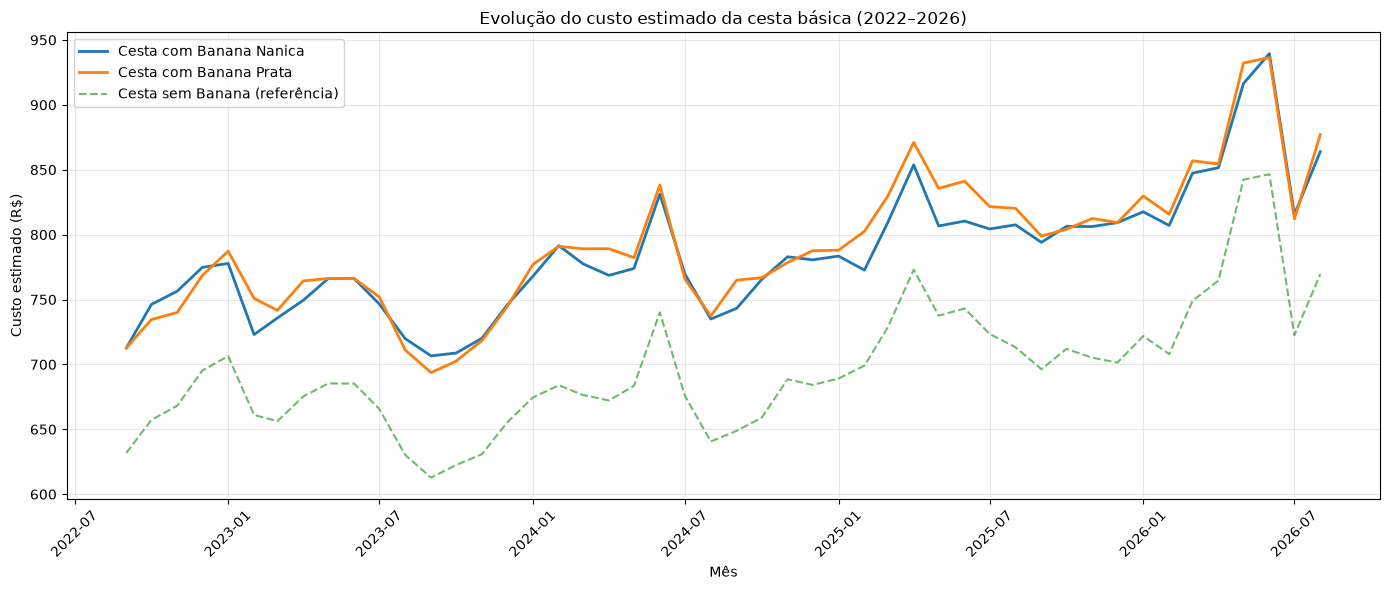

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    resultado_cesta["mes"],
    resultado_cesta["cesta_banana_nanica"],
    label="Cesta com Banana Nanica",
    linewidth=2
)

plt.plot(
    resultado_cesta["mes"],
    resultado_cesta["cesta_banana_prata"],
    label="Cesta com Banana Prata",
    linewidth=2
)

plt.plot(
    resultado_cesta["mes"],
    resultado_cesta["custo_sem_banana"],
    label="Cesta sem Banana (referência)",
    linestyle="--",
    alpha=0.7
)

plt.title("Evolução do custo estimado da cesta básica (2022–2026)")
plt.xlabel("Mês")
plt.ylabel("Custo estimado (R$)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()